LOAD DATASET
Dataset Shape: (569, 30)
Number of Features: 30
Number of Samples: 569

Class Names:
['malignant' 'benign']

DATA PREPROCESSING
Features standardized successfully.

Training Samples: 455
Testing Samples : 114

MODEL ARCHITECTURE


I0000 00:00:1791959209.157501      96 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1791959209.161282      96 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 1)              │            31 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31 (124.00 B)

 Trainable params: 31 (124.00 B)

 Non-trainable params: 0 (0.00 B)


TRAINING MODEL
Epoch 1/25
 1/12 ━━━━━━━━━━━━━━━━━━━━ 13s 1s/step - accuracy: 0.3750 - loss: 1.0010

I0000 00:00:1791959212.277528     142 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 77ms/step - accuracy: 0.3022 - loss: 1.0606 - val_accuracy: 0.4176 - val_loss: 0.8852
Epoch 2/25
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.3681 - loss: 0.9510 - val_accuracy: 0.4505 - val_loss: 0.7926
Epoch 3/25
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.4038 - loss: 0.8519 - val_accuracy: 0.5604 - val_loss: 0.7103
Epoch 4/25
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.4780 - loss: 0.7640 - val_accuracy: 0.6264 - val_loss: 0.6389
Epoch 5/25
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.5742 - loss: 0.6884 - val_accuracy: 0.7692 - val_loss: 0.5772
Epoch 6/25
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6676 - loss: 0.6209 - val_accuracy: 0.8352 - val_loss: 0.5268
Epoch 7/25
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7143 - loss: 0.5673 - val_accuracy: 0.8681 - val_loss: 0.4825
Epoch 8/25
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7775 - loss: 0.5201 - val_accuracy: 0.8791 - val_loss: 0.4451
Ep

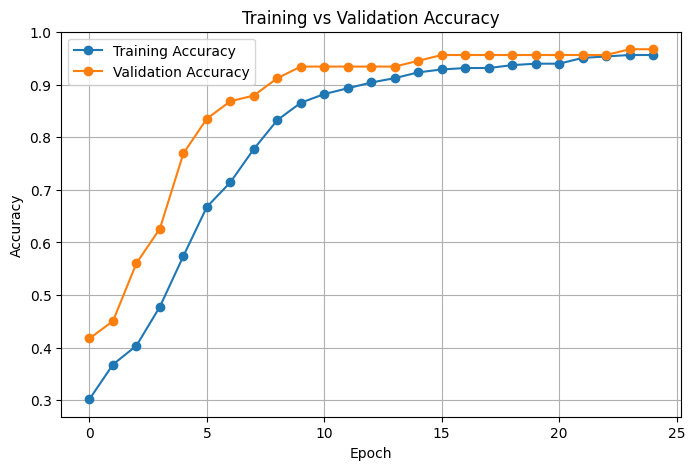

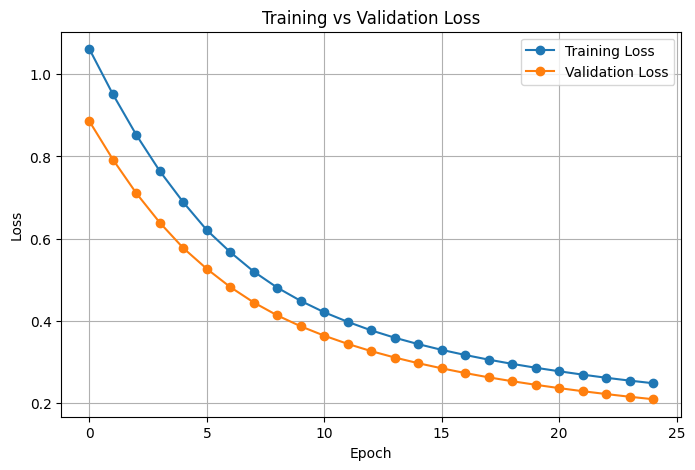


EXPLANATION OF CONCEPTS


1. ACTIVATION FUNCTION (SIGMOID)
--------------------------------
The sigmoid activation function converts the output
into a probability value between 0 and 1.

Formula:
σ(x) = 1 / (1 + e^-x)

It is used for binary classification because
predictions can be interpreted as class probabilities.

2. LOSS FUNCTION (BINARY CROSSENTROPY)
--------------------------------------
Binary Crossentropy measures the difference
between actual labels and predicted probabilities.

Lower loss indicates better model performance.

3. OPTIMIZER (ADAM)
-------------------
Adam updates the weights of the perceptron
during training to minimize the loss function.

Advantages:
- Fast convergence
- Adaptive learning rates
- Good performance on most datasets

4. EPOCHS
---------
One epoch means one complete pass through
the entire training dataset.

In this assignment, the model was trained for
25 epochs, meaning the learning process was
repeated 25 times.

5. SINGLE-LAYER PERCEPTRON
---

In [1]:
# ==========================================================
# ASSIGNMENT 5
# Single-Layer Perceptron using TensorFlow and Keras
# Binary Classification using Breast Cancer Dataset
# ==========================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam

# ==========================================================
# 1. LOAD DATASET
# ==========================================================

print("=" * 60)
print("LOAD DATASET")
print("=" * 60)

data = load_breast_cancer()

X = data.data
y = data.target

print("Dataset Shape:", X.shape)
print("Number of Features:", X.shape[1])
print("Number of Samples:", X.shape[0])

print("\nClass Names:")
print(data.target_names)

# ==========================================================
# 2. DATA PREPROCESSING
# ==========================================================

print("\n" + "=" * 60)
print("DATA PREPROCESSING")
print("=" * 60)

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Features standardized successfully.")

# ==========================================================
# 3. TRAIN-TEST SPLIT
# ==========================================================

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining Samples:", X_train.shape[0])
print("Testing Samples :", X_test.shape[0])

# ==========================================================
# 4. SINGLE-LAYER PERCEPTRON MODEL
# ==========================================================

print("\n" + "=" * 60)
print("MODEL ARCHITECTURE")
print("=" * 60)

model = Sequential([
    Dense(
        units=1,
        activation='sigmoid',
        input_shape=(X_train.shape[1],)
    )
])

# ==========================================================
# 5. COMPILE MODEL
# ==========================================================

model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

# ==========================================================
# 6. TRAIN MODEL (25 EPOCHS)
# ==========================================================

print("\n" + "=" * 60)
print("TRAINING MODEL")
print("=" * 60)

history = model.fit(
    X_train,
    y_train,
    epochs=25,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

# ==========================================================
# 7. EVALUATE MODEL
# ==========================================================

loss, accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("\n" + "=" * 60)
print("MODEL PERFORMANCE")
print("=" * 60)

print(f"Test Loss     : {loss:.4f}")
print(f"Test Accuracy : {accuracy:.4f}")

# ==========================================================
# 8. PREDICTIONS
# ==========================================================

y_prob = model.predict(X_test)

y_pred = (y_prob > 0.5).astype(int)

# ==========================================================
# 9. CLASSIFICATION REPORT
# ==========================================================

print("\n" + "=" * 60)
print("CLASSIFICATION REPORT")
print("=" * 60)

print(classification_report(y_test, y_pred))

# ==========================================================
# 10. CONFUSION MATRIX
# ==========================================================

print("\n" + "=" * 60)
print("CONFUSION MATRIX")
print("=" * 60)

cm = confusion_matrix(y_test, y_pred)

print(cm)

# ==========================================================
# 11. ACCURACY PLOT
# ==========================================================

plt.figure(figsize=(8,5))

plt.plot(
    history.history['accuracy'],
    label='Training Accuracy',
    marker='o'
)

plt.plot(
    history.history['val_accuracy'],
    label='Validation Accuracy',
    marker='o'
)

plt.title('Training vs Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.show()

# ==========================================================
# 12. LOSS PLOT
# ==========================================================

plt.figure(figsize=(8,5))

plt.plot(
    history.history['loss'],
    label='Training Loss',
    marker='o'
)

plt.plot(
    history.history['val_loss'],
    label='Validation Loss',
    marker='o'
)

plt.title('Training vs Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.show()

# ==========================================================
# 13. EXPLANATION OF KEY CONCEPTS
# ==========================================================

print("\n" + "=" * 60)
print("EXPLANATION OF CONCEPTS")
print("=" * 60)

print("""

1. ACTIVATION FUNCTION (SIGMOID)
--------------------------------
The sigmoid activation function converts the output
into a probability value between 0 and 1.

Formula:
σ(x) = 1 / (1 + e^-x)

It is used for binary classification because
predictions can be interpreted as class probabilities.

2. LOSS FUNCTION (BINARY CROSSENTROPY)
--------------------------------------
Binary Crossentropy measures the difference
between actual labels and predicted probabilities.

Lower loss indicates better model performance.

3. OPTIMIZER (ADAM)
-------------------
Adam updates the weights of the perceptron
during training to minimize the loss function.

Advantages:
- Fast convergence
- Adaptive learning rates
- Good performance on most datasets

4. EPOCHS
---------
One epoch means one complete pass through
the entire training dataset.

In this assignment, the model was trained for
25 epochs, meaning the learning process was
repeated 25 times.

5. SINGLE-LAYER PERCEPTRON
--------------------------
A Single-Layer Perceptron consists of:
- Input Layer
- One Output Neuron

There are no hidden layers.

The perceptron learns a linear decision boundary
for binary classification.
""")

# ==========================================================
# 14. FINAL CONCLUSION
# ==========================================================

print("\n" + "=" * 60)
print("CONCLUSION")
print("=" * 60)

print("""
A Single-Layer Perceptron was implemented using
TensorFlow and Keras for binary classification on
the Breast Cancer dataset.

The dataset was standardized using StandardScaler
and split into training and testing datasets.

The perceptron consisted of a single output neuron
with a Sigmoid activation function and was trained
for 25 epochs using the Adam optimizer and Binary
Crossentropy loss function.

Training and validation accuracy/loss plots showed
the learning progress of the model, while the
classification report and confusion matrix were
used to evaluate performance.

The model successfully classified samples into
their respective classes, demonstrating the
effectiveness of a Single-Layer Perceptron for
binary classification problems.
""")